In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt
import glob
import os
import datetime as dt
import xarray as xr
import re
import rioxarray
import geopandas as gpd
import gc
import matplotlib.pyplot as plt
from scipy.stats import linregress, t
import pwlf # piecewise linear regression
import pymannkendall as mk
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from tqdm import tqdm
import matplotlib.cm as cm
from matplotlib.collections import PatchCollection
from shapely.ops import unary_union
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import matplotlib.transforms as transforms
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm, LightSource, Normalize, ListedColormap, BoundaryNorm, LinearSegmentedColormap
import matplotlib.image as mpimg
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Polygon, Rectangle
from matplotlib.ticker import MultipleLocator
import piecewise_regression
import numpy as np
from scipy.stats import f as f_dist

import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from itertools import combinations

from config import data_folder, basin_names_list, Basins, bins, shapes
#### maybe also need years swe water years swe etc.

from figures import *


In [2]:
storm_ds_dict = {b: xr.open_dataset(os.path.join(data_folder, f'Data/Cleaned/{b}_grouped_storm_ds_final.nc4'))
                 for b in Basins}


## Figure 1

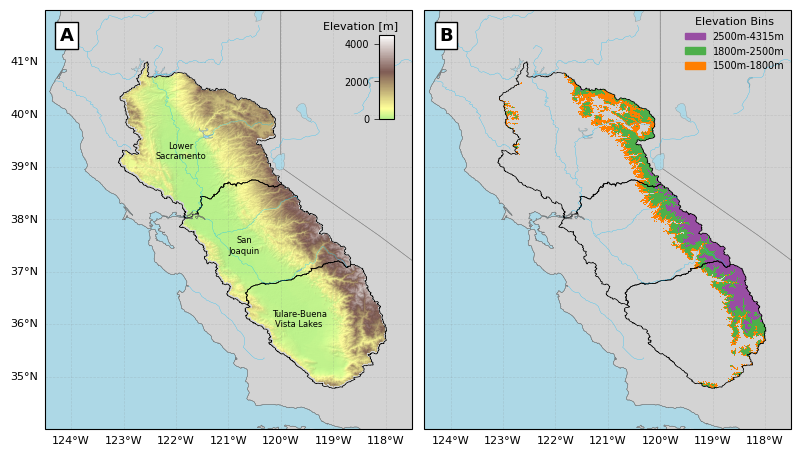

In [3]:
fig, axes = plot_dem_and_elev_bins()

bbox = fig.get_tightbbox(fig.canvas.get_renderer())
# the content's real extent, in inches

fig.set_size_inches(bbox.width, bbox.height)
plt.savefig("Figures/Fig1ab.pdf", dpi=600) #bbox_inches="tight",

plt.show()

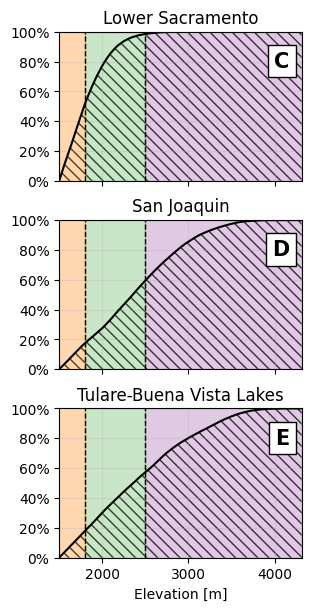

In [4]:
fig, axes = plot_elev_cdfs()

plt.savefig("Figures/Fig1cdef.pdf", bbox_inches="tight")

plt.show()

In [5]:
import fitz


src1 = fitz.open("Figures/Fig1ab.pdf")
r1 = src1[0].rect                      # the figure's true width and height
src2 = fitz.open("Figures/Fig1cdef.pdf")
r2 = src2[0].rect

combined_width = r1.width + ((r1.height / r2.height) * r2.width)

out = fitz.open()
page = out.new_page(width=combined_width, height=r1.height)


page.show_pdf_page(fitz.Rect(0, 0, r1.width, r1.height), src1, 0)



page.show_pdf_page(fitz.Rect(r1.width, 0, combined_width, r1.height), src2, 0)
out.save("Figures/Fig1.pdf")

## Table 1

In [6]:
summary = basin_summary(storm_ds_dict, decimals=None)
display(summary.round(1))
latex = basin_summary_latex(summary=summary, basins=Basins, path='Tables/basin_summary.tex')
print(latex)

/global/home/users/sarahryu/swe_elevation_warming/figures.py:1060: UserWarning: The specified chunks separate the stored chunks along dimension "Day" starting at index 100. This could degrade performance. Instead, consider rechunking after loading.
  prec = (xr.open_dataarray(prec_path, chunks={'Day': chunk_days})


,Area 1500–1800 m [km²],Area 1800–2500 m [km²],Area >2500 m [km²],Area >1500 m [km²],Max elevation [m],Mean elevation >1500 m [m],Mean precipitation [mm/yr],Mean peak SWE [mm],Mean storm temperature [°C],Storms per year
Lower Sacramento,5598.8,5051.3,170.6,10820.8,3112.6,1834.6,1289.6,383.8,-0.7,3.4
San Joaquin,1691.3,4037.7,3919.5,9648.5,4114.4,2384.8,1119.2,551.8,0.3,1.7
Tulare-Buena Vista Lakes,1783.5,3874.4,4182.8,9840.7,4315.4,2425.9,725.2,341.3,0.4,1.2
All basins,9073.6,12963.4,8272.9,30309.9,4315.4,2196.7,1052.1,423.5,-0.2,6.3


\begin{tabular}{lccc}
 & Lower Sacramento & San Joaquin & Tulare-Buena Vista Lakes  \\
\hline
Area [km$^2$] 
& $10821$ & $9648$ & $9841$
\\
Area, Elev. 1500--1800~m [km$^2$] 
& $5599 \ (52\%)$ & $1691 \ (18\%)$ & $1783 \ (18\%)$
\\
Area, Elev. 1800--2500~m [km$^2$] 
& $5051 \ (47\%)$ & $4038 \ (42\%)$ & $3874 \ (39\%)$
\\
Area, Elev. 2500--4315~m [km$^2$] 
& $171 \ (2\%)$ & $3919 \ (41\%)$ & $4183 \ (43\%)$
\\
Mean Elevation [m] 
& $1835$ & $2385$ & $2426$
\\
Max. Elevation [m] 
& $3113$ & $4114$ & $4315$
\\
Mean Precipitation [mm/yr] 
& $1290$ & $1119$ & $725$
\\
Mean Peak SWE (SWE$_\text{p}$) [mm/yr] 
& $384$ & $552$ & $341$
\\
Mean $\geq$200 mm Storm Temperature ($T_\text{storm}$) [$^\circ$C] 
& $-0.73$ & $0.27$ & $0.38$
\\
Mean $\geq$200 mm Storm Count [storms/yr] 
& $3.41$ & $1.68$ & $1.24$
\\
\hline
\end{tabular}


## Figure 2

01-20-1997


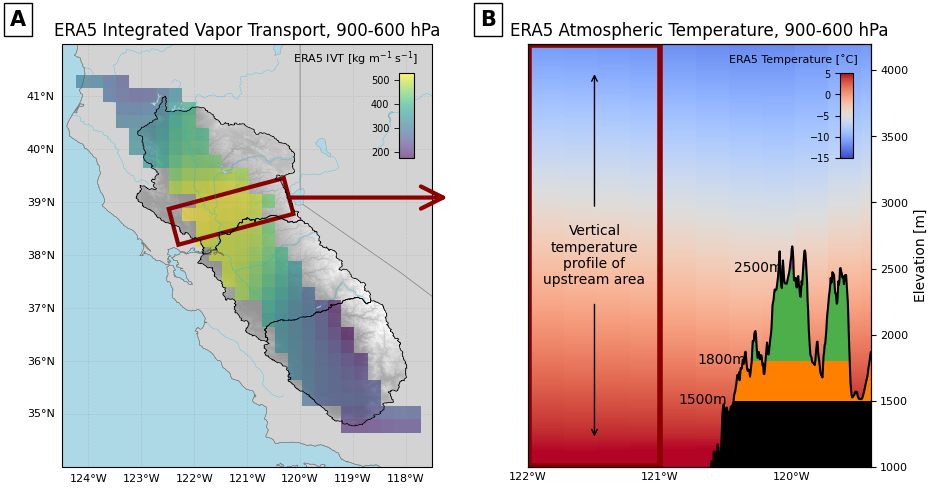

In [7]:
fig, (ax_map, ax_section) = plot_fig2(storm_ds_dict['SanJoaquin'])
fig.savefig('Figures/Fig2.pdf')
plt.show()

## Figure 3

In [4]:
storms = load_gridmet_storms()
print(f"{storms['Temperature'].count()} storms") # total number of storms analyzed here

prec_slope_das = calculate_slope_das(storm_precip_das(), 'Precipitation', 'P', storm_ds_dict,
                                     min_positive_count=1)


337 storms


/global/home/users/sarahryu/swe_elevation_warming/figures.py:569: UserWarning: The specified chunks separate the stored chunks along dimension "Day" starting at index 100. This could degrade performance. Instead, consider rechunking after loading.
  prec = xr.open_dataarray(prec_path, chunks={'Day': chunk_days}).sel(Day=days)


Exponential model: y = a * exp(b x)
a = 244.8
95% CI for a: [239.7, 250]
b = 0.08374
95% CI for b: [0.07531, 0.09216]
p-value: 2.665992742391918e-57


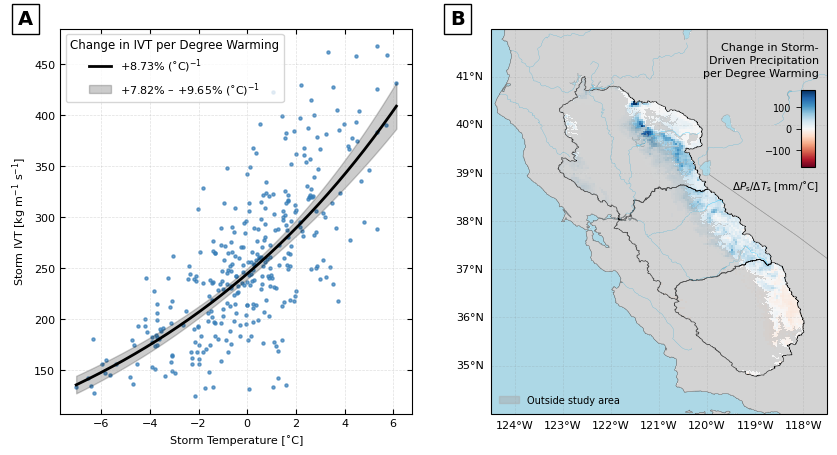

In [6]:
fig, (ax_fit, ax_map), (a, b) = plot_fig3(storms, prec_slope_das, prec_vlim=180) # values go up to about 200 mm
fig.savefig('Figures/Fig3.pdf')
plt.show()

## Figure 4

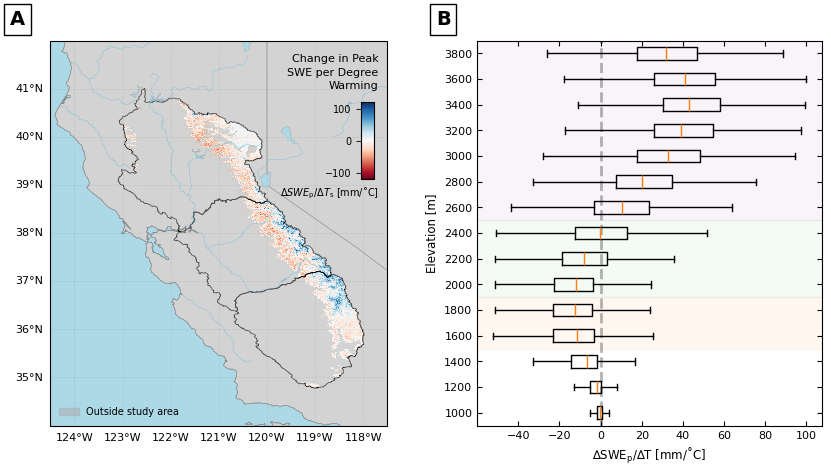

In [7]:
from figures import load_peak_swe, calculate_slope_das, slopes_by_elevation, plot_fig4

slope_das = calculate_slope_das(load_peak_swe(), 'SWE_Post', 'SWE_p', storm_ds_dict,
                                min_positive_fraction=0.5, scale=1000)
binned_slopes = slopes_by_elevation(slope_das)

fig, (ax_map, ax_box) = plot_fig4(slope_das, binned_slopes)
fig.savefig('Figures/Fig4.pdf')
plt.show()

## Figure 5

Lower Sacramento: N=126 storms
San Joaquin: N=62 storms
Tulare-Buena Vista Lakes: N=46 storms


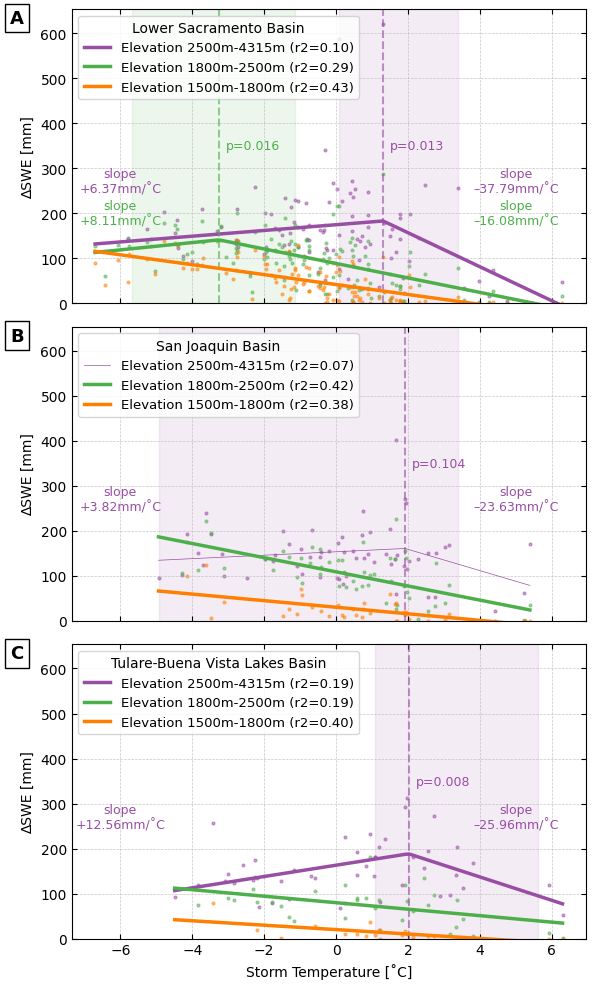

In [8]:
basin_dfs = create_basin_dfs(storm_ds_dict)
for basin, df in basin_dfs.items():
    print(f"{basin_names[basin]}: N={df['Temperature'].count()} storms")

fig = plot_piecewise_fit(basin_dfs, Basins, bin_lims=elev_bins[1:], size=(6, 10))
fig.savefig('Figures/Fig5.pdf')
plt.show()

## Figure S1

Type
CDEC      80
SNOTEL    23
Name: count, dtype: int64


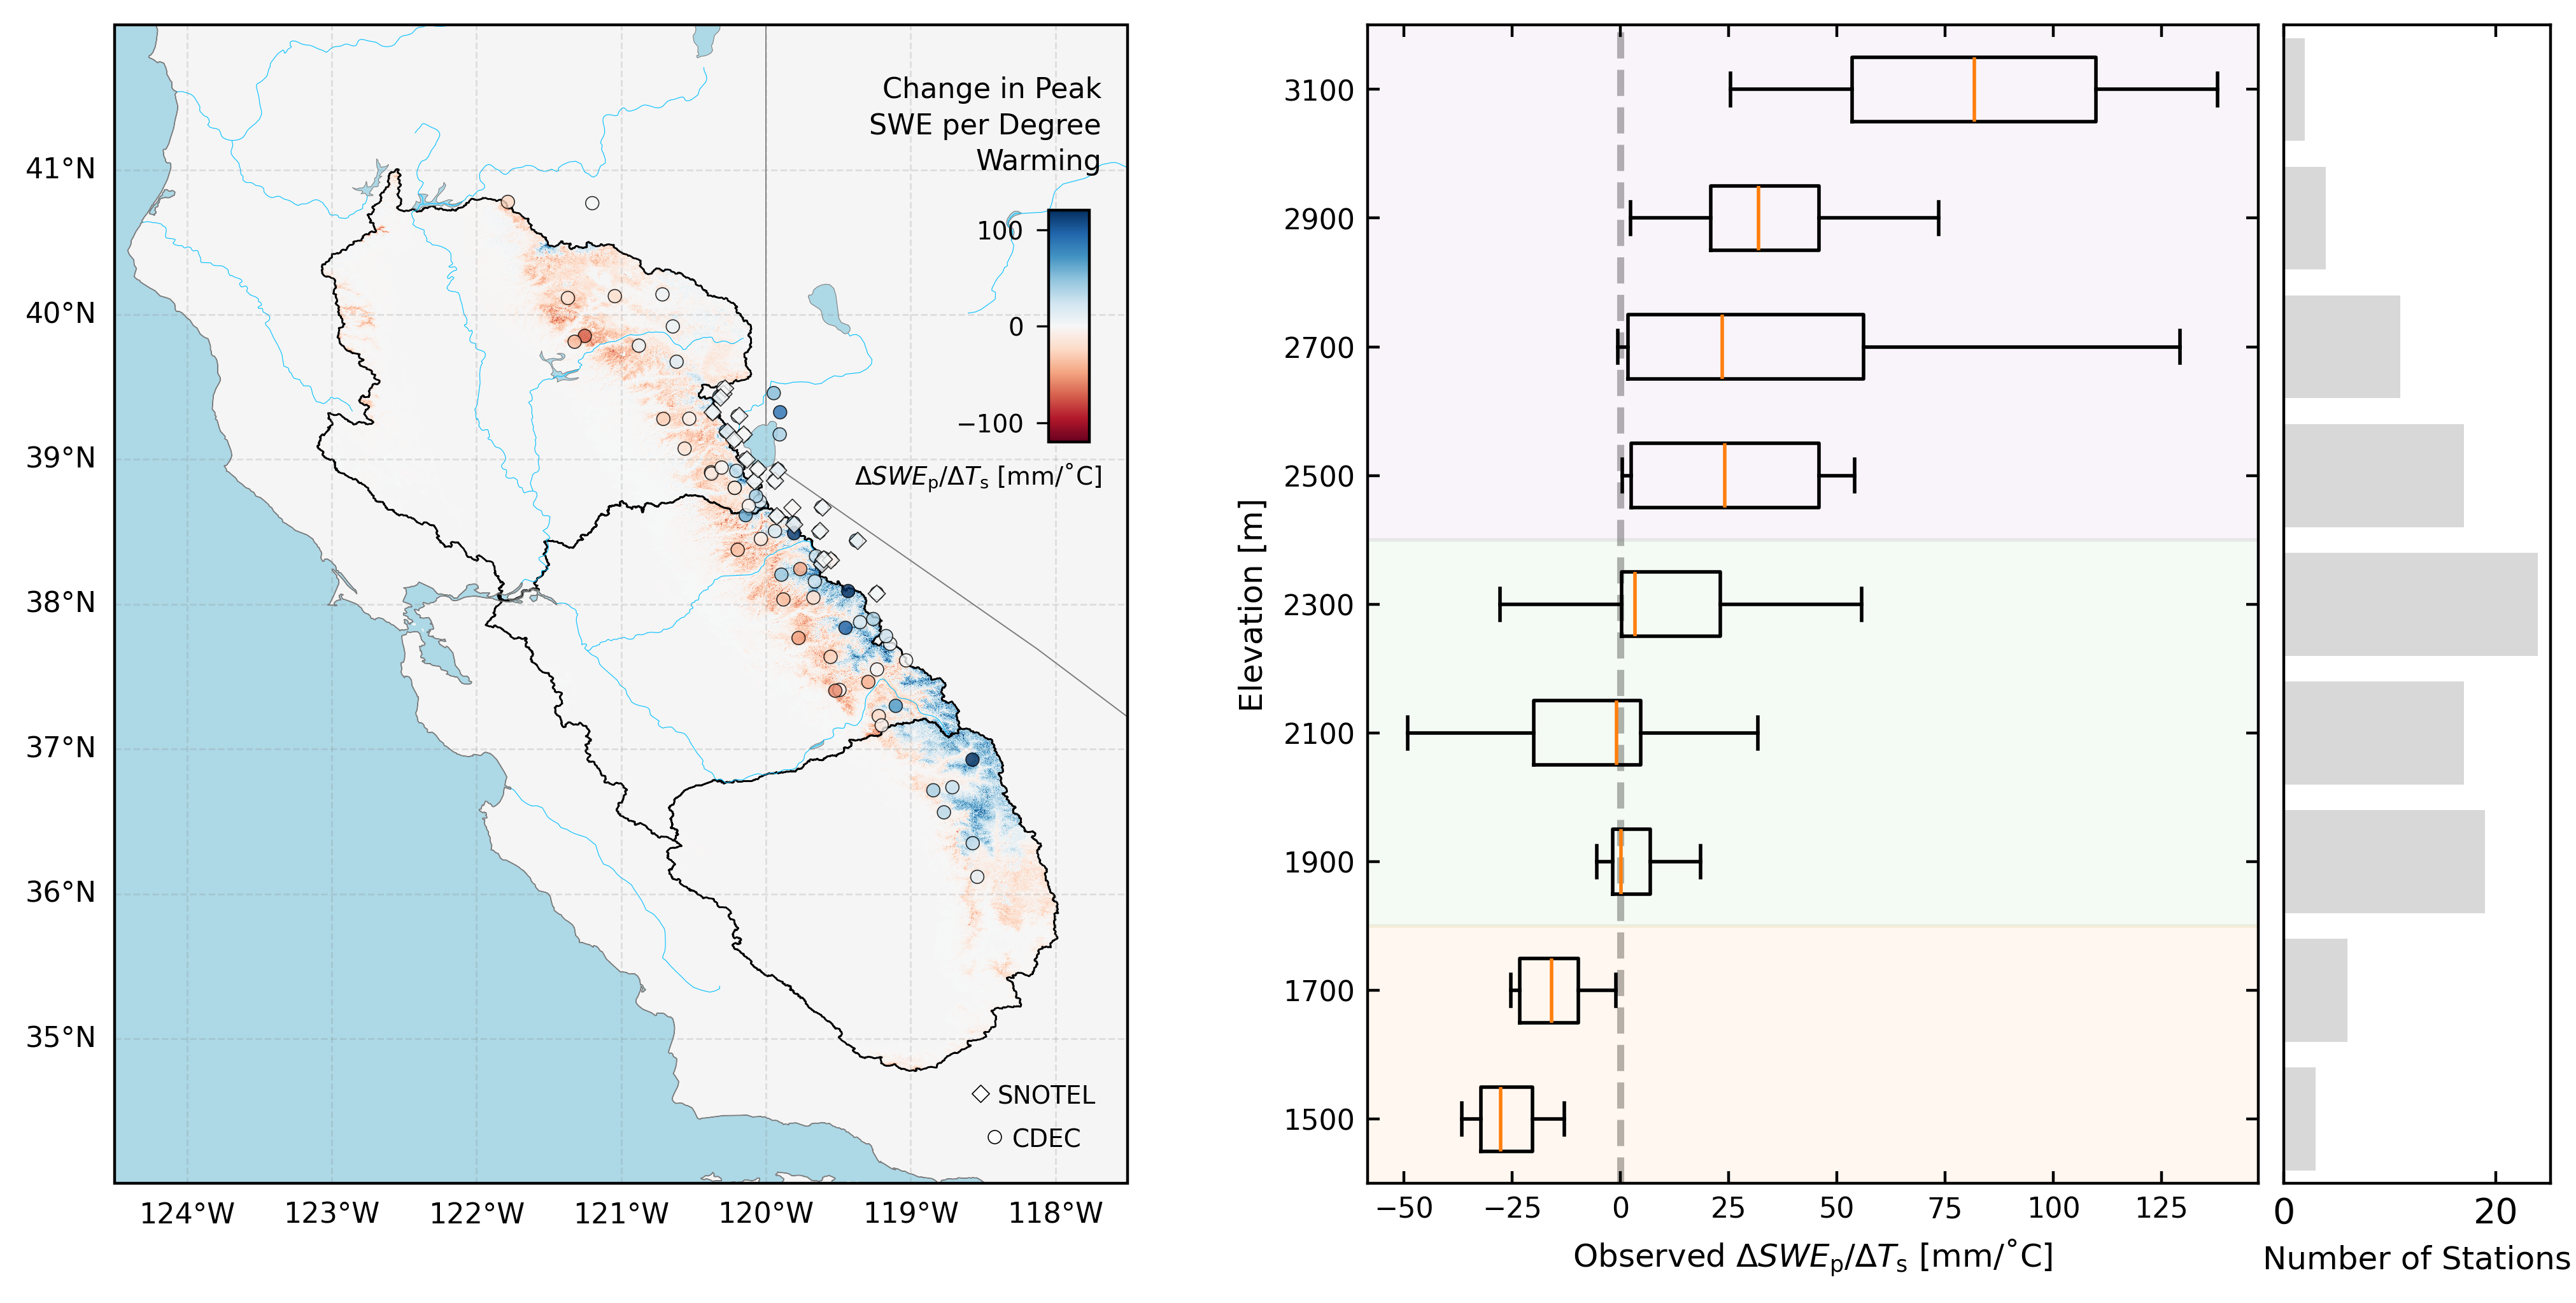

In [12]:
if 'slope_das' not in globals():  # reuse it if the Fig 4 cell already ran
    slope_das = calculate_slope_das(load_peak_swe(), 'SWE_Post', 'SWE_p', storm_ds_dict,
                                    min_positive_fraction=0.5, scale=1000)

station_df = clean_obs_data(storm_ds_dict)
print(station_df['Type'].value_counts())

fig, (ax_map, ax_box) = plot_figS1(slope_das, station_df)
fig.savefig('Figures/FigS1.pdf')
plt.show()

/global/home/users/sarahryu/SWE/.venv/lib/python3.11/site-packages/pwlf/pwlf.py:1248: RuntimeWarning: invalid value encountered in divide
  self.slopes = np.divide(


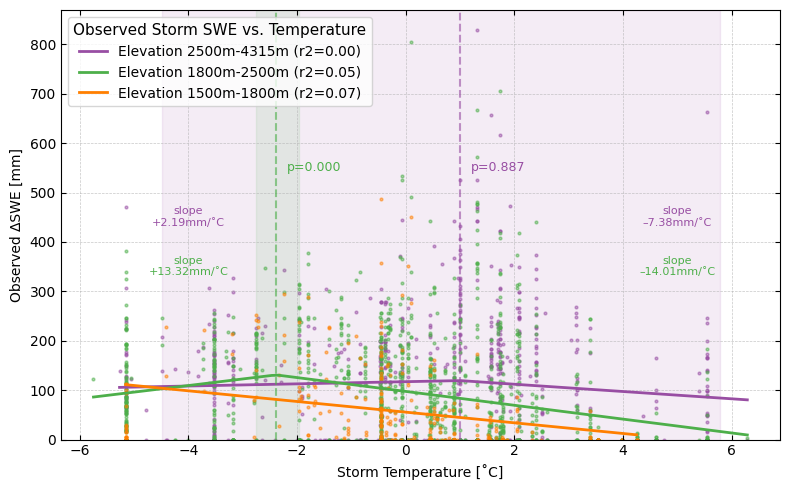

In [13]:
fig, ax = plt.subplots(figsize=(8,5)) #dpi=dpi
plot_piecewise_obs(ax)

plt.savefig("Figures/FigS2.pdf")

plt.show()

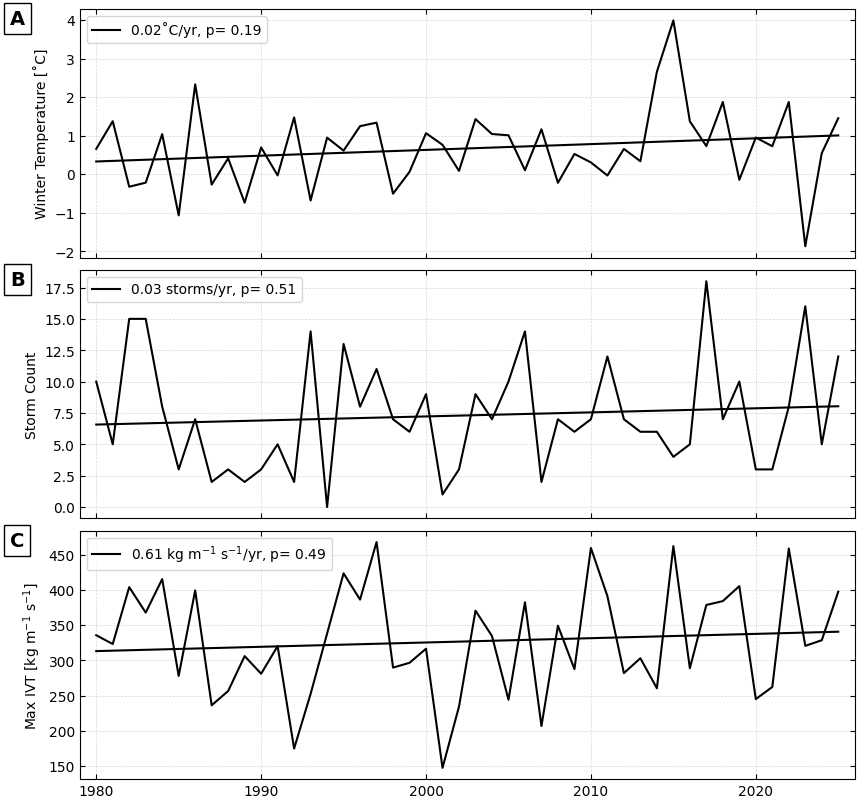

In [14]:
data = load_time_series_data()
fig, axes = plot_time_series(data)

plt.savefig('Figures/FigS3.pdf')
plt.show()

In [15]:
result = storm_swe_warming(storm_ds_dict, 'TulareBuenaVistaLakes', warmings=( 1.5, 3.0))

Tulare-Buena Vista Lakes: mean storm temperature 0.4 ˚C
  +1.5 ˚C: low/mid (1500–2500 m) -8 mm/yr (-0.046 km³/yr); high (>2500 m) +23 mm/yr (+0.098 km³/yr)
  +3 ˚C: low/mid (1500–2500 m) -16 mm/yr (-0.092 km³/yr); high (>2500 m) -18 mm/yr (-0.076 km³/yr)
